# UCS420: Cognitive Computing — Assignment 10
## Diabetes Care Information Assistant (odd roll number)
Aman Jha-1024170215

## 0. Setup

In [2]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.metrics.pairwise import cosine_similarity
warnings.filterwarnings("ignore")

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    try:
        nltk.download(pkg, quiet=True)
    except Exception:
        pass

## 1. Labelled Corpus (105 queries, 7 intent categories)

In [3]:
corpus = [
    # ---------- 1. types_of_diabetes ----------
    ("What is diabetes?", "types_of_diabetes"),
    ("What are the different types of diabetes?", "types_of_diabetes"),
    ("What is the difference between type 1 and type 2 diabetes?", "types_of_diabetes"),
    ("What is gestational diabetes in pregnancy?", "types_of_diabetes"),
    ("What does prediabetes mean?", "types_of_diabetes"),
    ("Is type 1 diabetes an autoimmune disease?", "types_of_diabetes"),
    ("Why does type 2 diabetes happen?", "types_of_diabetes"),
    ("Explain insulin resistance in type 2 diabetes", "types_of_diabetes"),
    ("Can children get type 1 diabetes?", "types_of_diabetes"),
    ("Is diabetes genetic or hereditary?", "types_of_diabetes"),
    ("Tell me about type 2 diabetes", "types_of_diabetes"),
    ("What causes type 1 diabetes?", "types_of_diabetes"),
    ("Who is at risk of developing diabetes?", "types_of_diabetes"),
    ("Can diabetes go away after pregnancy?", "types_of_diabetes"),
    ("Define juvenile diabetes", "types_of_diabetes"),

    # ---------- 2. symptoms_diagnosis ----------
    ("What are the symptoms of diabetes?", "symptoms_diagnosis"),
    ("What are the early warning signs of diabetes?", "symptoms_diagnosis"),
    ("I feel very thirsty and urinate frequently, is it diabetes?", "symptoms_diagnosis"),
    ("How is diabetes diagnosed?", "symptoms_diagnosis"),
    ("What is the HbA1c test used for diagnosis?", "symptoms_diagnosis"),
    ("What is a fasting plasma glucose test?", "symptoms_diagnosis"),
    ("What is an oral glucose tolerance test?", "symptoms_diagnosis"),
    ("Does blurred vision and tiredness indicate diabetes?", "symptoms_diagnosis"),
    ("Can sudden weight loss be a sign of diabetes?", "symptoms_diagnosis"),
    ("Which test confirms that I have diabetes?", "symptoms_diagnosis"),
    ("I have a dry mouth and pee a lot at night, do I have diabetes?", "symptoms_diagnosis"),
    ("How can I know if I am diabetic?", "symptoms_diagnosis"),
    ("What tests does a doctor do to check for diabetes?", "symptoms_diagnosis"),
    ("Constant hunger and fatigue, could it be sugar disease?", "symptoms_diagnosis"),
    ("At what HbA1c value is diabetes diagnosed?", "symptoms_diagnosis"),

    # ---------- 3. blood_sugar_monitoring ----------
    ("What is a normal blood sugar level?", "blood_sugar_monitoring"),
    ("How often should I check my blood glucose?", "blood_sugar_monitoring"),
    ("How do I use a glucometer at home?", "blood_sugar_monitoring"),
    ("What should my sugar level be after eating?", "blood_sugar_monitoring"),
    ("What is a continuous glucose monitor?", "blood_sugar_monitoring"),
    ("What is the target fasting sugar reading?", "blood_sugar_monitoring"),
    ("What HbA1c target should a diabetic aim for?", "blood_sugar_monitoring"),
    ("Why is my morning glucose reading high?", "blood_sugar_monitoring"),
    ("When is the best time to test blood sugar?", "blood_sugar_monitoring"),
    ("How do I keep a log of my glucose readings?", "blood_sugar_monitoring"),
    ("What range of sugar is considered safe?", "blood_sugar_monitoring"),
    ("How do I measure my sugar at home?", "blood_sugar_monitoring"),
    ("What is the ideal glucose value before breakfast?", "blood_sugar_monitoring"),
    ("Which glucose meter or sensor should I use for checking?", "blood_sugar_monitoring"),
    ("How many times a day should I test my sugar levels?", "blood_sugar_monitoring"),

    # ---------- 4. diet_nutrition ----------
    ("What foods should a diabetic eat?", "diet_nutrition"),
    ("Which foods should I avoid with diabetes?", "diet_nutrition"),
    ("Can diabetics eat rice?", "diet_nutrition"),
    ("Is fruit safe for people with diabetes?", "diet_nutrition"),
    ("What is the glycemic index of food?", "diet_nutrition"),
    ("Can I eat sweets or sugar if I have diabetes?", "diet_nutrition"),
    ("Suggest a healthy diabetic meal plan", "diet_nutrition"),
    ("How many carbohydrates should I eat per meal?", "diet_nutrition"),
    ("Are artificial sweeteners good for diabetics?", "diet_nutrition"),
    ("What breakfast is good for controlling sugar?", "diet_nutrition"),
    ("What should I not eat to keep my sugar under control?", "diet_nutrition"),
    ("Which items should a diabetic stay away from eating?", "diet_nutrition"),
    ("Is it okay for a diabetic to eat bananas and mangoes?", "diet_nutrition"),
    ("What snacks are healthy for diabetes?", "diet_nutrition"),
    ("Are potatoes and white bread bad for blood sugar?", "diet_nutrition"),

    # ---------- 5. medication_insulin ----------
    ("What medicines are used to treat diabetes?", "medication_insulin"),
    ("How does metformin work?", "medication_insulin"),
    ("What are the side effects of metformin?", "medication_insulin"),
    ("What are the different types of insulin?", "medication_insulin"),
    ("How do I inject insulin correctly?", "medication_insulin"),
    ("How should I store insulin pens?", "medication_insulin"),
    ("What happens if I miss a dose of my diabetes tablet?", "medication_insulin"),
    ("What is the difference between rapid acting and long acting insulin?", "medication_insulin"),
    ("Do all type 2 diabetics need insulin injections?", "medication_insulin"),
    ("Can I take diabetes pills with other drugs?", "medication_insulin"),
    ("What tablets are prescribed for sugar?", "medication_insulin"),
    ("Where on the body should I give my insulin shot?", "medication_insulin"),
    ("Can I keep my insulin outside the fridge?", "medication_insulin"),
    ("What is the use of glimepiride or sitagliptin?", "medication_insulin"),
    ("Does metformin cause stomach upset?", "medication_insulin"),

    # ---------- 6. exercise_lifestyle ----------
    ("Is exercise good for diabetes?", "exercise_lifestyle"),
    ("What kind of exercise is best for diabetics?", "exercise_lifestyle"),
    ("How much physical activity do I need per week?", "exercise_lifestyle"),
    ("Can walking lower my blood sugar?", "exercise_lifestyle"),
    ("How does weight loss help control diabetes?", "exercise_lifestyle"),
    ("Does stress affect diabetes?", "exercise_lifestyle"),
    ("How does sleep affect sugar control?", "exercise_lifestyle"),
    ("Should a diabetic quit smoking and alcohol?", "exercise_lifestyle"),
    ("Is yoga helpful for diabetes management?", "exercise_lifestyle"),
    ("Can lifestyle changes reverse prediabetes?", "exercise_lifestyle"),
    ("Which workouts help lower glucose?", "exercise_lifestyle"),
    ("Is gym training safe for a diabetic?", "exercise_lifestyle"),
    ("Does losing weight reduce sugar levels?", "exercise_lifestyle"),
    ("Can I drink beer if I have diabetes?", "exercise_lifestyle"),
    ("How do daily habits help manage diabetes?", "exercise_lifestyle"),

    # ---------- 7. complications ----------
    ("What are the complications of diabetes?", "complications"),
    ("How does diabetes affect the eyes?", "complications"),
    ("What is diabetic retinopathy?", "complications"),
    ("What is diabetic neuropathy and nerve damage?", "complications"),
    ("How does diabetes damage the kidneys?", "complications"),
    ("Why is foot care important for diabetics?", "complications"),
    ("Does diabetes increase the risk of heart disease?", "complications"),
    ("What is diabetic ketoacidosis?", "complications"),
    ("Why do wounds heal slowly in diabetes?", "complications"),
    ("What is hypoglycemia and why does it happen?", "complications"),
    ("Can high sugar damage my nerves and cause tingling in feet?", "complications"),
    ("Does diabetes lead to blindness?", "complications"),
    ("Why do diabetics get foot ulcers?", "complications"),
    ("Can diabetes cause kidney failure?", "complications"),
    ("What long term problems can uncontrolled sugar cause?", "complications"),
]

df = pd.DataFrame(corpus, columns=["query", "intent"])
print("Total queries:", len(df))
print(df["intent"].value_counts())
df.head(10)

Total queries: 105
intent
types_of_diabetes         15
symptoms_diagnosis        15
blood_sugar_monitoring    15
diet_nutrition            15
medication_insulin        15
exercise_lifestyle        15
complications             15
Name: count, dtype: int64


,query,intent
0,What is diabetes?,types_of_diabetes
1,What are the different types of diabetes?,types_of_diabetes
2,What is the difference between type 1 and type...,types_of_diabetes
3,What is gestational diabetes in pregnancy?,types_of_diabetes
4,What does prediabetes mean?,types_of_diabetes
5,Is type 1 diabetes an autoimmune disease?,types_of_diabetes
6,Why does type 2 diabetes happen?,types_of_diabetes
7,Explain insulin resistance in type 2 diabetes,types_of_diabetes
8,Can children get type 1 diabetes?,types_of_diabetes
9,Is diabetes genetic or hereditary?,types_of_diabetes


## 2. Hierarchical Taxonomy (5 major categories, 2–4 subcategories each)

In [4]:
taxonomy = {
    "Diabetes Care": {
        "Understanding Diabetes": {
            "Types of Diabetes": ["Type 1", "Type 2", "Gestational", "Prediabetes"],
            "Symptoms & Diagnosis": ["Warning Signs", "Diagnostic Tests (HbA1c, FPG, OGTT)"],
        },
        "Disease Management": {
            "Blood Sugar Monitoring": ["Target Ranges", "Glucometer / CGM", "Record Keeping"],
            "Medication & Insulin": ["Oral Medicines (Metformin)", "Insulin Types", "Injection & Storage"],
        },
        "Lifestyle": {
            "Diet & Nutrition": ["Carbohydrates", "Glycemic Index", "Meal Planning"],
            "Exercise & Habits": ["Physical Activity", "Weight, Sleep & Stress", "Smoking & Alcohol"],
        },
        "Complications": {
            "Acute Complications": ["Hypoglycemia", "Diabetic Ketoacidosis (DKA)"],
            "Chronic Complications": ["Retinopathy", "Neuropathy", "Nephropathy", "Cardiovascular", "Diabetic Foot"],
        },
        "Safety & Support": {
            "Emergency Situations": ["Severe Hypo / Hyperglycemia", "Unconsciousness", "Chest Pain"],
            "Out-of-Scope Queries": ["Non-diabetes Health Topics", "Personal Dosage Decisions"],
        },
    }
}

# Map every intent to its node in the taxonomy
intent_to_taxonomy = {
    "types_of_diabetes":      "Understanding Diabetes > Types of Diabetes",
    "symptoms_diagnosis":     "Understanding Diabetes > Symptoms & Diagnosis",
    "blood_sugar_monitoring": "Disease Management > Blood Sugar Monitoring",
    "medication_insulin":     "Disease Management > Medication & Insulin",
    "diet_nutrition":         "Lifestyle > Diet & Nutrition",
    "exercise_lifestyle":     "Lifestyle > Exercise & Habits",
    "complications":          "Complications > Acute / Chronic Complications",
}

def print_tree(node, indent=0):
    if isinstance(node, dict):
        for key, child in node.items():
            print("    " * indent + ("└── " if indent else "") + key)
            print_tree(child, indent + 1)
    else:
        for leaf in node:
            print("    " * indent + "└── " + leaf)

print_tree(taxonomy)

Diabetes Care
    └── Understanding Diabetes
        └── Types of Diabetes
            └── Type 1
            └── Type 2
            └── Gestational
            └── Prediabetes
        └── Symptoms & Diagnosis
            └── Warning Signs
            └── Diagnostic Tests (HbA1c, FPG, OGTT)
    └── Disease Management
        └── Blood Sugar Monitoring
            └── Target Ranges
            └── Glucometer / CGM
            └── Record Keeping
        └── Medication & Insulin
            └── Oral Medicines (Metformin)
            └── Insulin Types
            └── Injection & Storage
    └── Lifestyle
        └── Diet & Nutrition
            └── Carbohydrates
            └── Glycemic Index
            └── Meal Planning
        └── Exercise & Habits
            └── Physical Activity
            └── Weight, Sleep & Stress
            └── Smoking & Alcohol
    └── Complications
        └── Acute Complications
            └── Hypoglycemia
            └── Diabetic Ketoacidosis (DKA)
        

## 3. Domain Concepts and Relationships (12 concepts, 16 relationships)

In [5]:
concepts = {
    "Diabetes":       "Chronic condition with persistently high blood glucose",
    "Insulin":        "Hormone made by the pancreas that lets cells absorb glucose",
    "Blood Glucose":  "Amount of sugar circulating in the blood",
    "Pancreas":       "Organ whose beta cells produce insulin",
    "Type 1 Diabetes":"Autoimmune destruction of insulin-producing cells",
    "Type 2 Diabetes":"Insulin resistance with relative insulin deficiency",
    "HbA1c":          "Average blood glucose over ~3 months",
    "Metformin":      "First-line oral medicine for type 2 diabetes",
    "Diet":           "Food intake, especially carbohydrates",
    "Exercise":       "Physical activity that improves insulin sensitivity",
    "Hypoglycemia":   "Dangerously low blood glucose (< 70 mg/dL)",
    "Retinopathy":    "Damage to retinal blood vessels",
    "Neuropathy":     "Nerve damage, often in the feet",
    "Obesity":        "Excess body weight, major risk factor",
}

relationships = [
    ("Pancreas",        "produces",          "Insulin"),
    ("Insulin",         "lowers",            "Blood Glucose"),
    ("Type 1 Diabetes", "is_a",              "Diabetes"),
    ("Type 2 Diabetes", "is_a",              "Diabetes"),
    ("Type 1 Diabetes", "requires",          "Insulin"),
    ("Type 2 Diabetes", "first_treated_by",  "Metformin"),
    ("Metformin",       "lowers",            "Blood Glucose"),
    ("HbA1c",           "measures",          "Blood Glucose"),
    ("HbA1c",           "diagnoses",         "Diabetes"),
    ("Diet",            "affects",           "Blood Glucose"),
    ("Exercise",        "lowers",            "Blood Glucose"),
    ("Exercise",        "reduces",           "Obesity"),
    ("Obesity",         "risk_factor_for",   "Type 2 Diabetes"),
    ("Diabetes",        "causes",            "Retinopathy"),
    ("Diabetes",        "causes",            "Neuropathy"),
    ("Insulin",         "may_cause",         "Hypoglycemia"),
]

print(f"{len(concepts)} concepts, {len(relationships)} relationships\n")
rel_df = pd.DataFrame(relationships, columns=["Subject", "Relation", "Object"])
print(rel_df.to_string(index=False))

def related_concepts(concept):
    """Simple graph lookup used by the reasoning layer."""
    out = [(r, o) for s, r, o in relationships if s.lower() == concept.lower()]
    inc = [(s, r) for s, r, o in relationships if o.lower() == concept.lower()]
    return out, inc

14 concepts, 16 relationships

        Subject         Relation          Object
       Pancreas         produces         Insulin
        Insulin           lowers   Blood Glucose
Type 1 Diabetes             is_a        Diabetes
Type 2 Diabetes             is_a        Diabetes
Type 1 Diabetes         requires         Insulin
Type 2 Diabetes first_treated_by       Metformin
      Metformin           lowers   Blood Glucose
          HbA1c         measures   Blood Glucose
          HbA1c        diagnoses        Diabetes
           Diet          affects   Blood Glucose
       Exercise           lowers   Blood Glucose
       Exercise          reduces         Obesity
        Obesity  risk_factor_for Type 2 Diabetes
       Diabetes           causes     Retinopathy
       Diabetes           causes      Neuropathy
        Insulin        may_cause    Hypoglycemia


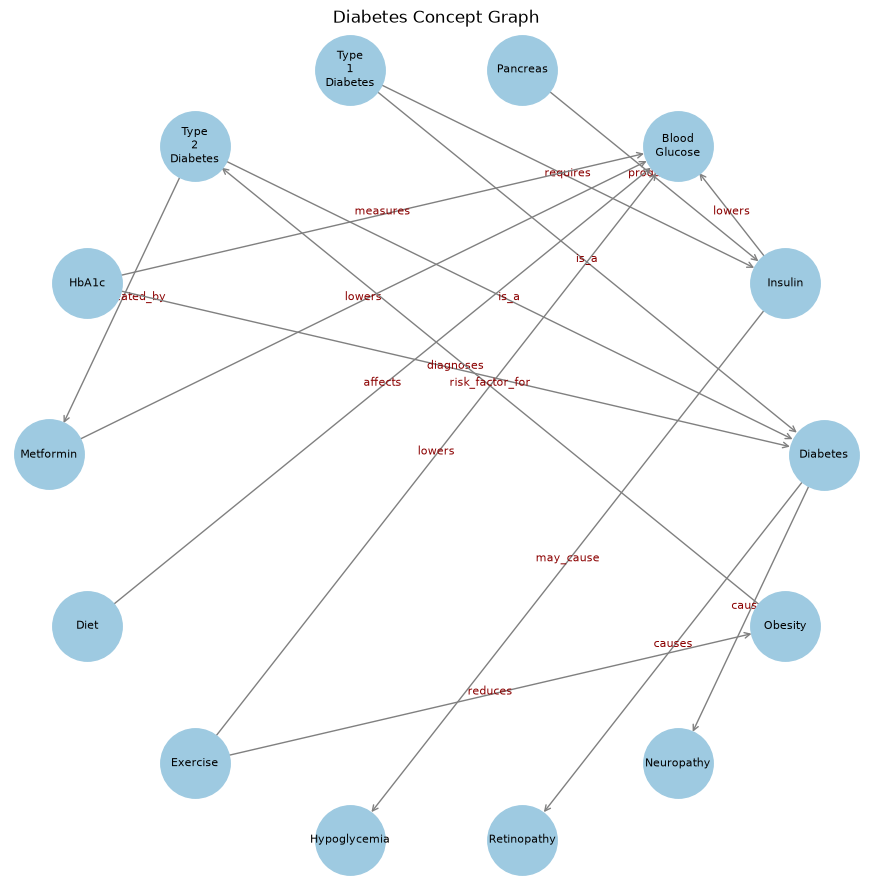

In [6]:
# Visualise the concept graph (circular layout, no extra libraries needed)
names = list(concepts)
angles = np.linspace(0, 2 * np.pi, len(names), endpoint=False)
pos = {n: (np.cos(a), np.sin(a)) for n, a in zip(names, angles)}
plt.figure(figsize=(11, 11))
for s, r, o in relationships:
    (x1, y1), (x2, y2) = pos[s], pos[o]
    plt.annotate("", xy=(x2, y2), xytext=(x1, y1),
                 arrowprops=dict(arrowstyle="->", color="gray", shrinkA=25, shrinkB=25))
    plt.text((x1 + x2) / 2, (y1 + y2) / 2, r, fontsize=8, color="darkred", ha="center")
for n, (x, y) in pos.items():
    plt.scatter(x, y, s=2500, color="#9ecae1", zorder=3)
    plt.text(x, y, n.replace(" ", "\n"), ha="center", va="center", fontsize=8, zorder=4)
plt.title("Diabetes Concept Graph")
plt.axis("off")
plt.show()

## 4. NLP Preprocessing
Lowercase conversion → tokenization → stopword removal → lemmatization → (extra) domain synonym normalisation.
Negations and words such as *before / after / high / low* are kept because they change the medical meaning.

In [7]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

try:
    STOPWORDS = set(stopwords.words("english"))
    lemmatizer = WordNetLemmatizer()
    lemmatizer.lemmatize("tests")
    word_tokenize("test sentence")
    NLTK_OK = True
except Exception as e:          # fallback if NLTK data cannot be downloaded
    print("NLTK data unavailable, using fallback:", e)
    STOPWORDS = set(ENGLISH_STOP_WORDS)
    NLTK_OK = False

# keep words that change meaning in a medical context
STOPWORDS -= {"not", "no", "after", "before", "during", "above", "below", "high", "low"}

def tokenize(text):
    return word_tokenize(text) if NLTK_OK else re.findall(r"[a-z0-9]+", text)

def lemmatize(tok):
    if NLTK_OK:
        return lemmatizer.lemmatize(lemmatizer.lemmatize(tok, pos="n"), pos="v")
    for suf in ("ing", "es", "s"):
        if tok.endswith(suf) and len(tok) > len(suf) + 2:
            return tok[: -len(suf)]
    return tok

# Domain synonym normalisation: maps lay words to the vocabulary the model knows
SYNONYMS = {"pee": "urinate", "urination": "urinate", "toilet": "urinate", "eatable": "food",
            "item": "food", "shot": "inject", "injection": "inject", "pill": "medicine",
            "tablet": "medicine", "drug": "medicine", "workout": "exercise", "gym": "exercise",
            "training": "exercise", "glucose": "sugar", "meter": "glucometer", "sensor": "glucometer",
            "diabetic": "diabetes", "beer": "alcohol", "fatigue": "tired", "tiredness": "tired"}

def preprocess(text, verbose=False):
    lower = text.lower()                                        # 1. lowercase
    tokens = tokenize(lower)                                    # 2. tokenize
    tokens = [t for t in tokens if re.fullmatch(r"[a-z0-9]+", t)]
    no_stop = [t for t in tokens if t not in STOPWORDS]         # 3. stopword removal
    lemmas = [lemmatize(t) for t in no_stop]                    # 4. lemmatization
    normal = [SYNONYMS.get(t, t) for t in lemmas]               # 5. synonym normalisation
    if verbose:
        print("Original   :", text)
        print("Lowercase  :", lower)
        print("Tokens     :", tokens)
        print("No stopword:", no_stop)
        print("Lemmatized :", lemmas)
        print("Normalised :", normal)
    return " ".join(normal)

preprocess("What are the early warning signs and symptoms of Diabetes in children?", verbose=True)
df["clean"] = df["query"].apply(preprocess)
df[["query", "clean", "intent"]].head(10)

Original   : What are the early warning signs and symptoms of Diabetes in children?
Lowercase  : what are the early warning signs and symptoms of diabetes in children?
Tokens     : ['what', 'are', 'the', 'early', 'warning', 'signs', 'and', 'symptoms', 'of', 'diabetes', 'in', 'children']
No stopword: ['early', 'warning', 'signs', 'symptoms', 'diabetes', 'children']
Lemmatized : ['early', 'warn', 'sign', 'symptom', 'diabetes', 'child']
Normalised : ['early', 'warn', 'sign', 'symptom', 'diabetes', 'child']


,query,clean,intent
0,What is diabetes?,diabetes,types_of_diabetes
1,What are the different types of diabetes?,different type diabetes,types_of_diabetes
2,What is the difference between type 1 and type...,difference type 1 type 2 diabetes,types_of_diabetes
3,What is gestational diabetes in pregnancy?,gestational diabetes pregnancy,types_of_diabetes
4,What does prediabetes mean?,prediabetes mean,types_of_diabetes
5,Is type 1 diabetes an autoimmune disease?,type 1 diabetes autoimmune disease,types_of_diabetes
6,Why does type 2 diabetes happen?,type 2 diabetes happen,types_of_diabetes
7,Explain insulin resistance in type 2 diabetes,explain insulin resistance type 2 diabetes,types_of_diabetes
8,Can children get type 1 diabetes?,child get type 1 diabetes,types_of_diabetes
9,Is diabetes genetic or hereditary?,diabetes genetic hereditary,types_of_diabetes


## 5. TF-IDF Feature Extraction + Logistic Regression Classifier

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["intent"], test_size=0.25, stratify=df["intent"], random_state=42)

from sklearn.pipeline import make_pipeline, make_union

def make_vectorizer():
    """TF-IDF on word uni/bi-grams + character n-grams (robust to spelling variants)."""
    return make_union(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
                      TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True))

vectorizer = make_vectorizer()
Xtr = vectorizer.fit_transform(X_train)
Xte = vectorizer.transform(X_test)
print("Train:", Xtr.shape, " Test:", Xte.shape)

clf = LogisticRegression(C=10, max_iter=2000)
clf.fit(Xtr, y_train)
y_pred = clf.predict(Xte)

Train: (78, 2649)  Test: (27, 2649)


## 6. Evaluation — Accuracy, Precision, Recall, F1, Confusion Matrix

Accuracy : 0.593
Precision: 0.595 (macro)
Recall   : 0.583 (macro)
F1-score : 0.581 (macro)

                        precision    recall  f1-score   support

blood_sugar_monitoring       0.33      0.33      0.33         3
         complications       0.50      0.25      0.33         4
        diet_nutrition       0.75      0.75      0.75         4
    exercise_lifestyle       0.50      0.50      0.50         4
    medication_insulin       1.00      1.00      1.00         4
    symptoms_diagnosis       0.75      0.75      0.75         4
     types_of_diabetes       0.33      0.50      0.40         4

              accuracy                           0.59        27
             macro avg       0.60      0.58      0.58        27
          weighted avg       0.60      0.59      0.59        27



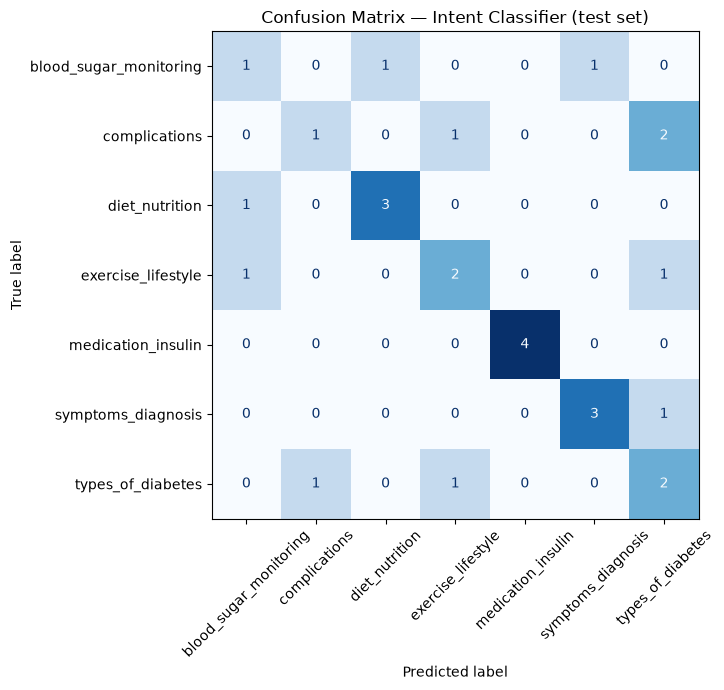

5-fold CV accuracy: 0.705 ± 0.063


In [9]:
print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, average='macro', zero_division=0):.3f} (macro)")
print(f"Recall   : {recall_score(y_test, y_pred, average='macro', zero_division=0):.3f} (macro)")
print(f"F1-score : {f1_score(y_test, y_pred, average='macro', zero_division=0):.3f} (macro)\n")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(df["intent"].unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("Confusion Matrix — Intent Classifier (test set)")
plt.tight_layout()
plt.show()

# 5-fold cross-validation gives a more stable estimate on a small corpus
cv_pipe = make_pipeline(make_vectorizer(), LogisticRegression(C=10, max_iter=2000))
cv = cross_val_score(cv_pipe, df["clean"], df["intent"],
                     cv=StratifiedKFold(5, shuffle=True, random_state=42))
print("5-fold CV accuracy: %.3f ± %.3f" % (cv.mean(), cv.std()))

In [10]:
# Retrain on the full corpus for deployment
vectorizer = make_vectorizer()
X_all = vectorizer.fit_transform(df["clean"])
clf = LogisticRegression(C=10, max_iter=2000).fit(X_all, df["intent"])
print("Final model trained on", X_all.shape[0], "queries,", X_all.shape[1], "features")

Final model trained on 105 queries, 3126 features


## 7. Domain-Specific Knowledge Base
Each intent has several entries. Within the predicted intent, the best entry is retrieved by
TF-IDF cosine similarity between the query and the entry's keywords.

In [11]:
knowledge_base = {
    "types_of_diabetes": [
        {"topic": "What is diabetes", "keywords": "diabetes what is definition meaning chronic glucose",
         "answer": "Diabetes is a chronic condition in which blood glucose stays too high because the body either does not make enough insulin or cannot use it properly."},
        {"topic": "Type 1 vs Type 2", "keywords": "type 1 type 2 difference autoimmune insulin resistance children genetic hereditary",
         "answer": "Type 1 diabetes is an autoimmune condition where the pancreas makes little or no insulin; it often starts in childhood and always needs insulin. Type 2 diabetes is caused by insulin resistance plus reduced insulin production; it is linked to genetics, weight and inactivity and is usually managed with lifestyle changes, tablets and sometimes insulin."},
        {"topic": "Gestational diabetes", "keywords": "gestational pregnancy pregnant",
         "answer": "Gestational diabetes develops during pregnancy (usually 24–28 weeks) and normally resolves after delivery, but it raises the mother's later risk of type 2 diabetes."},
        {"topic": "Prediabetes", "keywords": "prediabetes borderline risk",
         "answer": "Prediabetes means blood sugar is above normal but below the diabetes range (HbA1c 5.7–6.4%, fasting glucose 100–125 mg/dL). It can often be reversed with weight loss and regular activity."},
    ],
    "symptoms_diagnosis": [
        {"topic": "Symptoms", "keywords": "symptom sign warning early thirsty urinate frequent tired blurred vision weight loss hungry",
         "answer": "Common symptoms are excessive thirst, frequent urination, increased hunger, unexplained weight loss, tiredness, blurred vision, slow-healing wounds and frequent infections. Type 2 diabetes may have no symptoms early on."},
        {"topic": "Diagnostic tests", "keywords": "diagnose diagnosis test confirm hba1c fasting plasma glucose tolerance ogtt",
         "answer": "Diabetes is diagnosed with any of: HbA1c ≥ 6.5%, fasting plasma glucose ≥ 126 mg/dL, 2-hour OGTT glucose ≥ 200 mg/dL, or a random glucose ≥ 200 mg/dL with symptoms. Abnormal results are usually repeated to confirm."},
    ],
    "blood_sugar_monitoring": [
        {"topic": "Target ranges", "keywords": "normal level target range fasting after eating meal reading hba1c aim",
         "answer": "Typical targets for most adults with diabetes: fasting/pre-meal 80–130 mg/dL, 2 hours after meals below 180 mg/dL, and HbA1c below 7%. (Non-diabetic fasting levels are 70–99 mg/dL.) Your doctor may set personal targets."},
        {"topic": "How to check", "keywords": "glucometer use check test home how often time best cgm continuous monitor",
         "answer": "Wash and dry hands, insert a strip into the glucometer, prick the side of a fingertip, apply the drop and record the reading. People on insulin may test several times a day; others less often. A continuous glucose monitor (CGM) uses a small sensor under the skin to track glucose every few minutes."},
        {"topic": "Morning highs & logging", "keywords": "morning high dawn phenomenon log record diary",
         "answer": "High morning readings can result from the dawn phenomenon (early-morning hormones), a late-night snack, or medication timing. Keep a log of date, time, reading, food, activity and medicines and share it with your doctor."},
    ],
    "diet_nutrition": [
        {"topic": "Healthy foods", "keywords": "food eat good healthy meal plan breakfast vegetable whole grain",
         "answer": "Fill half the plate with non-starchy vegetables, a quarter with lean protein (dal, eggs, fish, chicken, paneer) and a quarter with whole grains. Good breakfast options: oats, vegetable upma, besan chilla or eggs with whole-wheat toast."},
        {"topic": "Foods to limit", "keywords": "avoid not eat stay away limit bad sweet sugar rice potato white bread dessert sweetener artificial juice",
         "answer": "Limit sugary drinks, sweets, refined flour and fried foods. Rice can be eaten in small portions (brown rice is better) paired with vegetables and protein. Artificial sweeteners are generally safe in moderation."},
        {"topic": "Carbs & glycemic index", "keywords": "carbohydrate carb glycemic index gi fruit portion",
         "answer": "The glycemic index (GI) shows how fast a food raises blood sugar. Prefer low-GI foods (legumes, oats, most whole fruits) over high-GI foods (white bread, sugary cereal). Many adults aim for about 45–60 g carbohydrate per meal, adjusted by a dietitian. Whole fruits are fine in measured portions; avoid fruit juice."},
    ],
    "medication_insulin": [
        {"topic": "Oral medicines", "keywords": "medicine tablet pill metformin drug work side effect treat",
         "answer": "Metformin is usually the first medicine for type 2 diabetes; it lowers liver glucose output and improves insulin sensitivity. Common side effects are nausea and diarrhoea, reduced by taking it with food. Other classes include sulfonylureas, DPP-4 inhibitors, SGLT2 inhibitors and GLP-1 agonists. Always tell your doctor about other drugs you take."},
        {"topic": "Insulin types", "keywords": "insulin type rapid short long acting basal bolus need",
         "answer": "Insulin types: rapid-acting (works in ~15 min, for meals), short-acting, intermediate-acting, and long-acting/basal (steady 24-hour coverage). Everyone with type 1 needs insulin; some people with type 2 need it when other treatments are not enough."},
        {"topic": "Injection & storage", "keywords": "inject injection pen store storage fridge miss dose",
         "answer": "Inject into the fatty tissue of the abdomen, thigh or upper arm and rotate sites. Store unopened insulin in the fridge (2–8 °C, never frozen); an in-use pen can stay at room temperature for about 28 days. If you miss a dose, follow your doctor's instructions — do not double up without advice."},
    ],
    "exercise_lifestyle": [
        {"topic": "Exercise", "keywords": "exercise physical activity walk walking yoga best kind week",
         "answer": "Aim for at least 150 minutes of moderate activity per week (e.g. 30 min brisk walking, 5 days) plus strength training twice a week. Exercise improves insulin sensitivity and lowers blood sugar; check sugar before exercise if you use insulin and carry a fast-acting snack."},
        {"topic": "Weight, sleep & stress", "keywords": "weight loss stress sleep reverse prediabetes lifestyle change",
         "answer": "Losing 5–10% of body weight can greatly improve control and can reverse prediabetes. Stress hormones and poor sleep raise blood sugar, so aim for 7–8 hours of sleep and practise stress management (yoga, breathing, meditation)."},
        {"topic": "Smoking & alcohol", "keywords": "smoking smoke quit alcohol drink",
         "answer": "Quit smoking — it multiplies the risk of heart, kidney and foot complications. If you drink alcohol, do so in moderation and with food, as alcohol can cause delayed low blood sugar."},
    ],
    "complications": [
        {"topic": "Overview", "keywords": "complication risk heart disease long term",
         "answer": "Long-term high blood sugar damages blood vessels and nerves, raising the risk of heart attack and stroke, kidney disease, eye disease, nerve damage and foot ulcers. Good control of sugar, blood pressure and cholesterol reduces these risks."},
        {"topic": "Eyes & kidneys", "keywords": "eye retinopathy vision kidney nephropathy",
         "answer": "Diabetic retinopathy damages the retina's blood vessels and can cause blindness — get a dilated eye exam every year. Diabetic nephropathy damages the kidneys — check urine albumin and creatinine yearly."},
        {"topic": "Nerves & feet", "keywords": "neuropathy nerve damage foot feet care wound heal slowly",
         "answer": "Diabetic neuropathy causes numbness, tingling or pain, mostly in the feet. Combined with poor circulation, small wounds heal slowly and can become ulcers. Inspect your feet daily, keep them clean and dry, and wear well-fitting footwear."},
        {"topic": "Acute: hypo & DKA", "keywords": "hypoglycemia low sugar ketoacidosis dka ketone",
         "answer": "Hypoglycemia (glucose < 70 mg/dL) causes shaking, sweating and confusion — treat with the 15-15 rule: 15 g fast sugar, recheck after 15 minutes. Diabetic ketoacidosis (DKA) is a dangerous build-up of ketones, mostly in type 1, causing vomiting, abdominal pain and rapid breathing; it needs emergency care."},
    ],
}

# Pre-compute TF-IDF vectors for knowledge base retrieval
kb_vectorizer = TfidfVectorizer()
kb_vectorizer.fit([preprocess(e["keywords"] + " " + e["topic"])
                   for entries in knowledge_base.values() for e in entries] + list(df["clean"]))
kb_matrix = {intent: kb_vectorizer.transform([preprocess(e["keywords"] + " " + e["topic"]) for e in entries])
             for intent, entries in knowledge_base.items()}

def retrieve(intent, clean_query):
    sims = cosine_similarity(kb_vectorizer.transform([clean_query]), kb_matrix[intent])[0]
    best = int(np.argmax(sims))
    return knowledge_base[intent][best], float(sims[best])

for intent, entries in knowledge_base.items():
    print(f"{intent:25s} → {len(entries)} entries: {[e['topic'] for e in entries]}")

types_of_diabetes         → 4 entries: ['What is diabetes', 'Type 1 vs Type 2', 'Gestational diabetes', 'Prediabetes']
symptoms_diagnosis        → 2 entries: ['Symptoms', 'Diagnostic tests']
blood_sugar_monitoring    → 3 entries: ['Target ranges', 'How to check', 'Morning highs & logging']
diet_nutrition            → 3 entries: ['Healthy foods', 'Foods to limit', 'Carbs & glycemic index']
medication_insulin        → 3 entries: ['Oral medicines', 'Insulin types', 'Injection & storage']
exercise_lifestyle        → 3 entries: ['Exercise', 'Weight, sleep & stress', 'Smoking & alcohol']
complications             → 4 entries: ['Overview', 'Eyes & kidneys', 'Nerves & feet', 'Acute: hypo & DKA']


## 8. Rule-Based Reasoning Engine (8 rules)

| # | Rule | Trigger | Action |
|---|------|---------|--------|
| R1 | **Emergency escalation** | emergency keywords, or glucose < 54 / > 400 mg/dL | Urgent advice + call emergency services (108/112) |
| R2 | Empty input | blank query | Ask for a question |
| R3 | Greeting / farewell / thanks | small-talk words | Friendly reply |
| R4 | **Unsupported healthcare query** | non-diabetes medical topic, or no known vocabulary | Politely decline, refer to a doctor |
| R5 | Glucose reading interpretation | a number with mg/dL / "sugar is N" | Classify the reading (low / normal / high) |
| R6 | Personal dosage request | "how much insulin should I take" | Refuse specific dosing, refer to doctor |
| R7 | **Low confidence** | classifier confidence < threshold | Ask for clarification, show top-2 guesses |
| R8 | Medical disclaimer | every answered query | Append disclaimer |

In [12]:
CONFIDENCE_THRESHOLD = 0.45

EMERGENCY_PATTERNS = [
    r"unconscious", r"passed out", r"faint", r"collapse", r"seizure", r"fit[s]? ", r"convulsion",
    r"chest pain", r"can'?t breathe", r"cannot breathe", r"difficulty breathing", r"short(ness)? of breath",
    r"not responding", r"unresponsive", r"confused and sweating", r"severe(ly)? confus",
    r"vomiting.*(ketone|sugar|diabet)", r"fruity breath", r"ketoacidosis.*(now|right now|having)",
    r"having a stroke", r"having a heart attack", r"emergency", r"dying", r"very low sugar", r"extremely (high|low)",
]

UNSUPPORTED_TERMS = [
    "cancer", "tumor", "covid", "corona", "malaria", "dengue", "typhoid", "tuberculosis", "asthma",
    "migraine", "fracture", "broken bone", "acne", "skin rash", "hair loss", "toothache", "dental",
    "depression", "anxiety", "pregnancy test", "fever", "cold", "cough", "flu", "thyroid", "arthritis",
    "allergy", "hiv", "hepatitis", "kidney stone", "back pain", "eczema", "psoriasis", "autism",
]
DOMAIN_TERMS = ["diabet", "sugar", "glucose", "insulin", "hba1c", "metformin", "glycemic", "carb",
                "pancrea", "ketone", "hypo", "hyper", "glucometer", "a1c"]

GREETINGS = {"hi", "hello", "hey", "namaste", "good morning", "good evening", "good afternoon"}
FAREWELLS = {"bye", "goodbye", "exit", "quit", "see you"}
THANKS = {"thanks", "thank you", "thx"}

DISCLAIMER = ("ℹ️ This is general educational information, not a medical diagnosis. "
              "Please consult your doctor for personal advice.")

def extract_glucose(text):
    m = re.search(r"(\d{2,3})\s*(mg\s*/?\s*dl|mg)", text.lower()) or \
        re.search(r"(sugar|glucose|reading|level)\D{0,15}(\d{2,3})", text.lower())
    if not m:
        return None
    return int(m.group(1) if m.group(1).isdigit() else m.group(2))

def interpret_glucose(v, text=""):
    fasting = bool(re.search(r"fasting|empty stomach|before (breakfast|meal|food|eating)|morning", text.lower()))
    if fasting and 70 <= v <= 250:
        if v <= 130: return "normal", f"A fasting reading of {v} mg/dL is within the usual diabetic target (80–130 mg/dL)."
        return "high", f"A fasting reading of {v} mg/dL is ABOVE the usual target (80–130 mg/dL). Review diet, medicines and evening snacks with your doctor."
    if v < 54:   return "critical", f"A reading of {v} mg/dL is SEVERE HYPOGLYCEMIA."
    if v < 70:   return "low",  f"A reading of {v} mg/dL is LOW (hypoglycemia). Take 15 g of fast-acting sugar (glucose tablets, ½ cup juice), recheck in 15 minutes, and repeat if still below 70."
    if v <= 130: return "normal", f"A reading of {v} mg/dL is within the usual fasting/pre-meal target (80–130 mg/dL)."
    if v < 180:  return "normal", f"A reading of {v} mg/dL is acceptable after a meal (target < 180 mg/dL) but above the fasting target."
    if v <= 250: return "high", f"A reading of {v} mg/dL is HIGH. Drink water, follow your treatment plan, recheck later and inform your doctor if it stays high."
    if v <= 400: return "high", f"A reading of {v} mg/dL is VERY HIGH. Check ketones if you have type 1 diabetes, drink water and contact your doctor today."
    return "critical", f"A reading of {v} mg/dL is DANGEROUSLY HIGH."

def emergency_response(reason):
    return ("🚨 EMERGENCY — " + reason + "\n"
            "• Call emergency services immediately (India: 108 / 112).\n"
            "• If the person is conscious and sugar may be LOW, give fast-acting sugar (glucose, juice).\n"
            "• If unconscious, do NOT give food or drink by mouth; place them on their side.\n"
            "• Stay with the person until help arrives.")

def contains_any(text, terms):
    return any(re.search(r"\b" + re.escape(t), text) for t in terms)

## 9. Integrated Cognitive Assistant
Pipeline: **input → NLP preprocessing → rule engine (pre-checks) → intent classification →
confidence check → knowledge retrieval → response generation**.

In [13]:
class DiabetesCareAssistant:
    def __init__(self, vectorizer, clf, threshold=CONFIDENCE_THRESHOLD):
        self.vec, self.clf, self.threshold = vectorizer, clf, threshold
        self.word_vocab = vectorizer.transformer_list[0][1].vocabulary_

    def classify(self, clean):
        probs = self.clf.predict_proba(self.vec.transform([clean]))[0]
        order = np.argsort(probs)[::-1]
        return [(self.clf.classes_[i], float(probs[i])) for i in order]

    def respond(self, query):
        """Returns a dict describing the reasoning trace and final answer."""
        q = query.strip()
        low = q.lower()
        trace = {"query": q, "clean": None, "intent": None, "confidence": None, "rule": None}

        # R2: empty input
        if not q:
            trace.update(rule="R2 Empty input", answer="Please type a question about diabetes.")
            return trace

        # R1: emergency escalation (highest priority)
        glucose = extract_glucose(q)
        if any(re.search(p, low + " ") for p in EMERGENCY_PATTERNS):
            trace.update(rule="R1 Emergency escalation",
                         answer=emergency_response("your message describes a potentially life-threatening situation."))
            return trace
        if glucose is not None and interpret_glucose(glucose, q)[0] == "critical":
            trace.update(rule="R1 Emergency escalation (critical glucose)",
                         answer=emergency_response(interpret_glucose(glucose, q)[1]))
            return trace

        # R3: greetings / thanks / farewell
        words = set(re.findall(r"[a-z]+", low))
        if low in GREETINGS or (words & {"hi", "hello", "hey", "namaste"} and len(words) <= 3):
            trace.update(rule="R3 Greeting", answer="Hello! 👋 I'm your Diabetes Care Assistant. Ask me about types, symptoms, sugar monitoring, diet, medicines, exercise or complications.")
            return trace
        if contains_any(low, THANKS) and len(words) <= 4:
            trace.update(rule="R3 Thanks", answer="You're welcome! Stay healthy. 😊")
            return trace
        if low in FAREWELLS:
            trace.update(rule="R3 Farewell", answer="Goodbye! Take care of your health. 👋")
            return trace

        clean = preprocess(q)
        trace["clean"] = clean

        # R4: unsupported healthcare query
        in_domain = contains_any(low, DOMAIN_TERMS)
        if contains_any(low, UNSUPPORTED_TERMS) and not in_domain:
            trace.update(rule="R4 Unsupported healthcare query",
                         answer="⚠️ Sorry, that health topic is outside my scope. I only provide diabetes-care information. Please consult a doctor or an appropriate specialist for this concern.")
            return trace
        known = [t for t in clean.split() if t in self.word_vocab]
        if not known and glucose is None:
            trace.update(rule="R4 Unsupported / out-of-domain query",
                         answer="⚠️ I couldn't relate your question to diabetes care. I can help with: types of diabetes, symptoms & diagnosis, blood sugar monitoring, diet, medicines & insulin, exercise & lifestyle, and complications.")
            return trace

        # R5: glucose reading interpretation
        if glucose is not None:
            trace.update(rule="R5 Glucose reading interpretation", intent="blood_sugar_monitoring",
                         answer=interpret_glucose(glucose, q)[1] + "\n\n" + DISCLAIMER)
            return trace

        # R6: personal dosage request
        if re.search(r"how (much|many) (unit|units|insulin|mg|tablet|dose)|what dose|increase my dose|dosage (should|for me)|units? of insulin should", low):
            trace.update(rule="R6 Personal dosage request", intent="medication_insulin",
                         answer="💊 I can't recommend a personal dose. Insulin and medicine doses depend on your weight, readings, diet and other conditions and must be set by your doctor or diabetes educator.\n\n" + DISCLAIMER)
            return trace

        # Intent classification
        ranked = self.classify(clean)
        intent, conf = ranked[0]
        trace.update(intent=intent, confidence=conf, top2=ranked[:2])

        # R7: low confidence handling
        if conf < self.threshold:
            opts = " or ".join(f"'{i.replace('_', ' ')}'" for i, _ in ranked[:2])
            trace.update(rule="R7 Low confidence",
                         answer=f"🤔 I'm not fully sure what you mean (confidence {conf:.0%}). Are you asking about {opts}? Please rephrase with more detail.")
            return trace

        # Knowledge retrieval + R8 disclaimer
        entry, sim = retrieve(intent, clean)
        trace.update(rule="R8 Answer + disclaimer", kb_topic=entry["topic"], kb_similarity=sim,
                     answer=f"📘 [{intent_to_taxonomy[intent]} › {entry['topic']}]\n{entry['answer']}\n\n{DISCLAIMER}")
        return trace

assistant = DiabetesCareAssistant(vectorizer, clf)

def show(query):
    r = assistant.respond(query)
    print("🧑 You       :", r["query"])
    if r.get("clean"):      print("   cleaned   :", r["clean"])
    if r.get("intent"):     print("   intent    :", r["intent"],
                                  f"(confidence {r['confidence']:.2f})" if r.get("confidence") is not None else "")
    print("   rule fired:", r["rule"])
    print("🤖 Assistant :", r["answer"])
    print("-" * 100)

## 10. Testing the Assistant
### 10.1 One query for each defined intent

In [14]:
intent_tests = [
    "Explain how type 1 differs from type 2",                       # types_of_diabetes
    "What signs tell me I might have diabetes?",                     # symptoms_diagnosis
    "What reading is normal before breakfast?",                      # blood_sugar_monitoring
    "Which foods are good for a diabetic diet?",                     # diet_nutrition
    "What are the side effects of metformin tablets?",               # medication_insulin
    "How much exercise should a diabetic do every week?",            # exercise_lifestyle
    "Can diabetes cause kidney damage?",                             # complications
]
for q in intent_tests:
    show(q)

🧑 You       : Explain how type 1 differs from type 2
   cleaned   : explain type 1 differ type 2
   intent    : types_of_diabetes (confidence 0.85)
   rule fired: R8 Answer + disclaimer
🤖 Assistant : 📘 [Understanding Diabetes > Types of Diabetes › Type 1 vs Type 2]
Type 1 diabetes is an autoimmune condition where the pancreas makes little or no insulin; it often starts in childhood and always needs insulin. Type 2 diabetes is caused by insulin resistance plus reduced insulin production; it is linked to genetics, weight and inactivity and is usually managed with lifestyle changes, tablets and sometimes insulin.

ℹ️ This is general educational information, not a medical diagnosis. Please consult your doctor for personal advice.
----------------------------------------------------------------------------------------------------
🧑 You       : What signs tell me I might have diabetes?
   cleaned   : sign tell might diabetes
   intent    : symptoms_diagnosis (confidence 0.56)
   rule fired: 

### 10.2 Differently worded query

In [15]:
show("My mouth is always dry and I keep running to the toilet at night — could that mean I'm diabetic?")
show("Which eatables must I stay away from to keep my glucose under control?")

🧑 You       : My mouth is always dry and I keep running to the toilet at night — could that mean I'm diabetic?
   cleaned   : mouth always dry keep run urinate night could mean diabetes
   intent    : symptoms_diagnosis (confidence 0.68)
   rule fired: R8 Answer + disclaimer
🤖 Assistant : 📘 [Understanding Diabetes > Symptoms & Diagnosis › Symptoms]
Common symptoms are excessive thirst, frequent urination, increased hunger, unexplained weight loss, tiredness, blurred vision, slow-healing wounds and frequent infections. Type 2 diabetes may have no symptoms early on.

ℹ️ This is general educational information, not a medical diagnosis. Please consult your doctor for personal advice.
----------------------------------------------------------------------------------------------------
🧑 You       : Which eatables must I stay away from to keep my glucose under control?
   cleaned   : food must stay away keep sugar control
   intent    : diet_nutrition (confidence 0.80)
   rule fired: R8 Answe

### 10.3 Unsupported healthcare query

In [16]:
show("What is the treatment for a migraine?")
show("How do I treat dengue fever?")

🧑 You       : What is the treatment for a migraine?
   cleaned   : treatment migraine
   rule fired: R4 Unsupported healthcare query
🤖 Assistant : ⚠️ Sorry, that health topic is outside my scope. I only provide diabetes-care information. Please consult a doctor or an appropriate specialist for this concern.
----------------------------------------------------------------------------------------------------
🧑 You       : How do I treat dengue fever?
   cleaned   : treat dengue fever
   rule fired: R4 Unsupported healthcare query
🤖 Assistant : ⚠️ Sorry, that health topic is outside my scope. I only provide diabetes-care information. Please consult a doctor or an appropriate specialist for this concern.
----------------------------------------------------------------------------------------------------


### 10.4 Low-confidence query

In [17]:
show("Tell me about the levels")
show("is it bad")

🧑 You       : Tell me about the levels
   cleaned   : tell level
   intent    : blood_sugar_monitoring (confidence 0.39)
   rule fired: R7 Low confidence
🤖 Assistant : 🤔 I'm not fully sure what you mean (confidence 39%). Are you asking about 'blood sugar monitoring' or 'exercise lifestyle'? Please rephrase with more detail.
----------------------------------------------------------------------------------------------------
🧑 You       : is it bad
   cleaned   : bad
   intent    : diet_nutrition (confidence 0.39)
   rule fired: R7 Low confidence
🤖 Assistant : 🤔 I'm not fully sure what you mean (confidence 39%). Are you asking about 'diet nutrition' or 'complications'? Please rephrase with more detail.
----------------------------------------------------------------------------------------------------


### 10.5 Emergency-related query

In [18]:
show("My father is diabetic and has become unconscious, what do I do?")
show("My sugar is 35 mg/dl and I am shaking")

🧑 You       : My father is diabetic and has become unconscious, what do I do?
   rule fired: R1 Emergency escalation
🤖 Assistant : 🚨 EMERGENCY — your message describes a potentially life-threatening situation.
• Call emergency services immediately (India: 108 / 112).
• If the person is conscious and sugar may be LOW, give fast-acting sugar (glucose, juice).
• If unconscious, do NOT give food or drink by mouth; place them on their side.
• Stay with the person until help arrives.
----------------------------------------------------------------------------------------------------
🧑 You       : My sugar is 35 mg/dl and I am shaking
   rule fired: R1 Emergency escalation (critical glucose)
🤖 Assistant : 🚨 EMERGENCY — A reading of 35 mg/dL is SEVERE HYPOGLYCEMIA.
• Call emergency services immediately (India: 108 / 112).
• If the person is conscious and sugar may be LOW, give fast-acting sugar (glucose, juice).
• If unconscious, do NOT give food or drink by mouth; place them on their side.
• 

### 10.6 Other rules (greeting, glucose interpretation, dosage request)

In [19]:
show("Hello")
show("My fasting sugar is 145 mg/dl, is that okay?")
show("How much insulin should I take tonight?")

🧑 You       : Hello
   rule fired: R3 Greeting
🤖 Assistant : Hello! 👋 I'm your Diabetes Care Assistant. Ask me about types, symptoms, sugar monitoring, diet, medicines, exercise or complications.
----------------------------------------------------------------------------------------------------
🧑 You       : My fasting sugar is 145 mg/dl, is that okay?
   cleaned   : fast sugar 145 okay
   intent    : blood_sugar_monitoring 
   rule fired: R5 Glucose reading interpretation
🤖 Assistant : A fasting reading of 145 mg/dL is ABOVE the usual target (80–130 mg/dL). Review diet, medicines and evening snacks with your doctor.

ℹ️ This is general educational information, not a medical diagnosis. Please consult your doctor for personal advice.
----------------------------------------------------------------------------------------------------
🧑 You       : How much insulin should I take tonight?
   cleaned   : much insulin take tonight
   intent    : medication_insulin 
   rule fired: R6 Persona

## 11. Deployment — Interactive Interface in Google Colab
Type a question and press **Ask** (or Enter). The chat history keeps all previous queries and answers.
Type `clear` to reset the conversation.

In [20]:
import html
import ipywidgets as widgets
from IPython.display import display, HTML

chat_log = []
text_box = widgets.Text(placeholder="Ask about diabetes care… e.g. 'What is a normal sugar level?'",
                        layout=widgets.Layout(width="75%"))
ask_btn = widgets.Button(description="Ask", button_style="primary")
clear_btn = widgets.Button(description="Clear", button_style="warning")
out = widgets.Output(layout=widgets.Layout(border="1px solid #ccc", padding="8px",
                                           max_height="520px", overflow="auto"))

def render():
    out.clear_output()
    with out:
        blocks = []
        for q, r in chat_log:
            meta = r["rule"]
            if r.get("intent") and r.get("confidence") is not None:
                meta += f" · intent: {r['intent']} ({r['confidence']:.0%})"
            colour = "#fdecea" if r["rule"].startswith("R1") else "#eef6ff"
            blocks.append(
                f"<div style='margin:6px 0'><b>🧑 You:</b> {html.escape(q)}</div>"
                f"<div style='background:{colour};padding:8px;border-radius:6px;white-space:pre-wrap'>"
                f"<b>🤖 Assistant:</b> {html.escape(r['answer'])}"
                f"<div style='color:#777;font-size:11px;margin-top:4px'>{html.escape(meta)}</div></div>")
        display(HTML("".join(blocks) or "<i>No messages yet.</i>"))

def on_ask(_=None):
    q = text_box.value
    text_box.value = ""
    if q.strip().lower() == "clear":
        chat_log.clear()
    else:
        chat_log.append((q, assistant.respond(q)))
    render()

def on_clear(_):
    chat_log.clear()
    render()

ask_btn.on_click(on_ask)
clear_btn.on_click(on_clear)
text_box.on_submit(on_ask)

display(HTML("<h3>🩺 Diabetes Care Information Assistant</h3>"))
display(widgets.HBox([text_box, ask_btn, clear_btn]), out)
render()

Output(layout=Layout(border_bottom='1px solid #ccc', border_left='1px solid #ccc', border_right='1px solid #cc…